## Section 2: Model 1 – Classification Tree with All Predictors

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

In [2]:
# Load preprocessed training and testing datasets
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze('columns')
y_test = pd.read_csv('y_test.csv').squeeze('columns')

In [3]:
# Build a classification tree using all predictors
model1 = DecisionTreeClassifier(
    criterion='entropy',
    min_samples_leaf=50,
    random_state=42
)

# Fit the model on the training data
model1.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sam

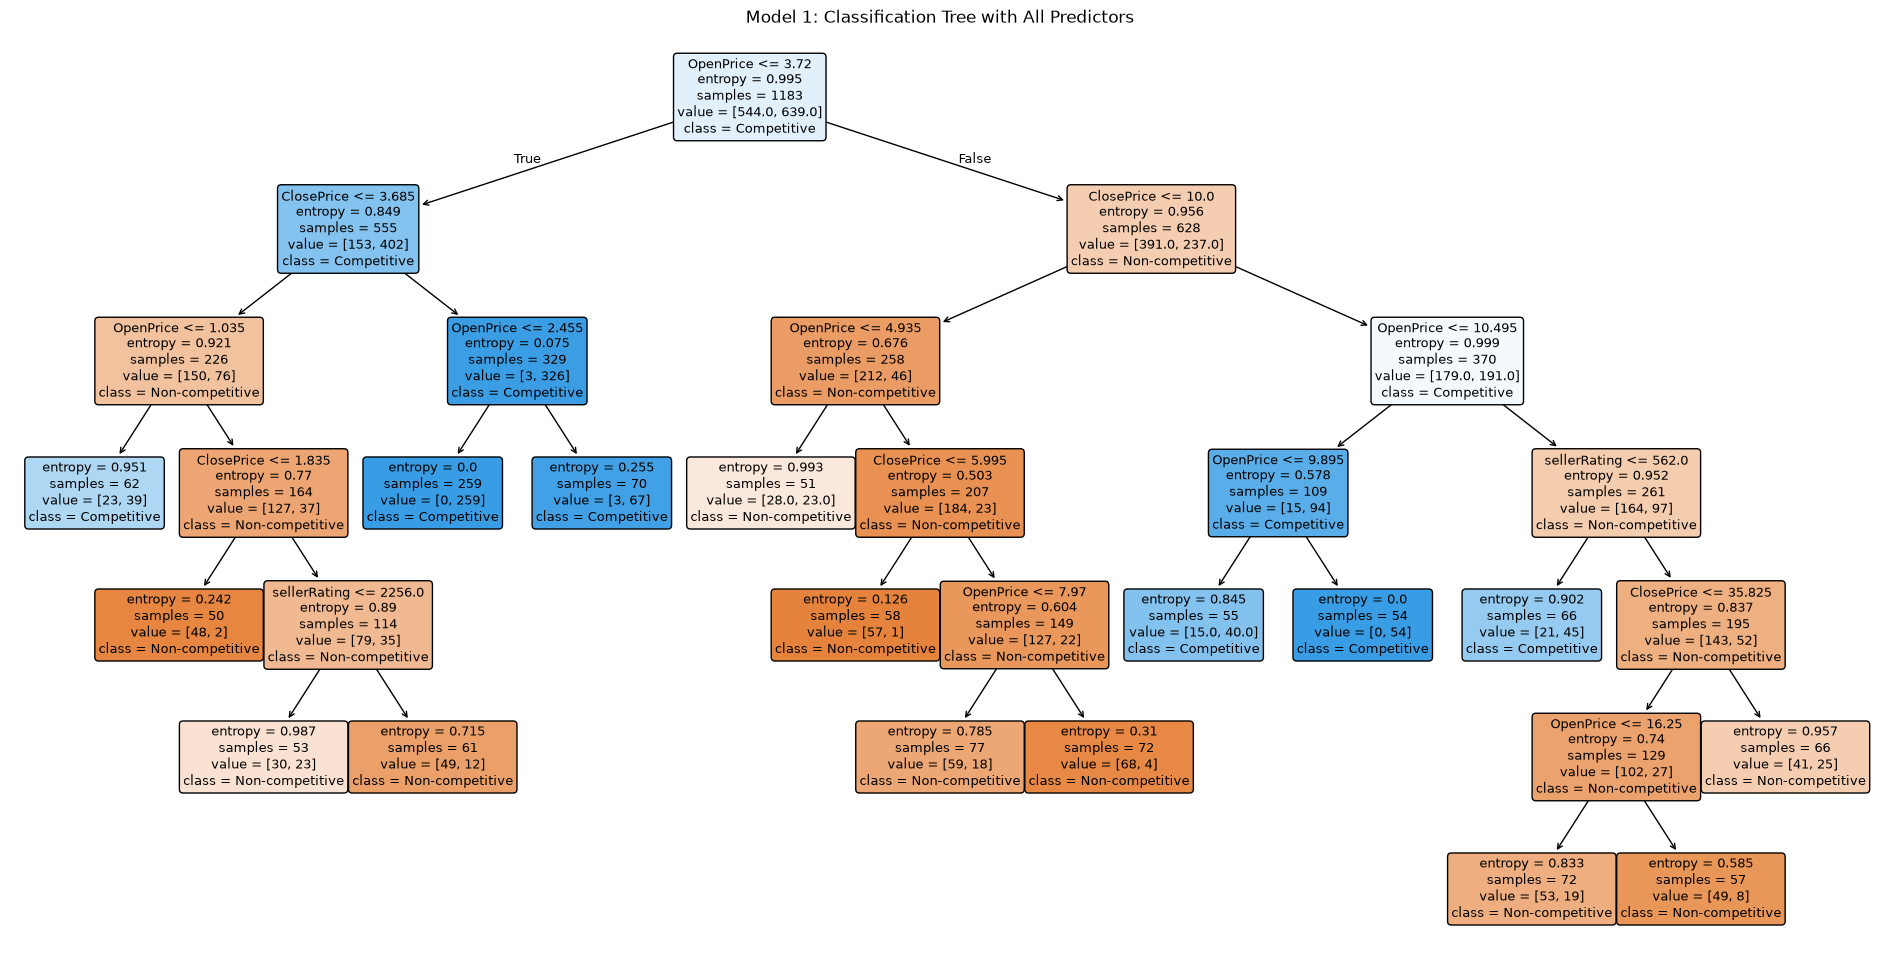

In [4]:
# Visualize Model 1 Tree
plt.figure(figsize=(24, 12))

plot_tree(
    model1,
    feature_names=X_train.columns,
    class_names=['Non-competitive', 'Competitive'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Model 1: Classification Tree with All Predictors')
plt.show()

In [5]:
# Check the number of terminal nodes and tree depth
print("Number of terminal nodes:", model1.get_n_leaves())
print("Tree depth:", model1.get_depth())

Number of terminal nodes: 16
Tree depth: 6


### 2.1 Model Building and Decision Rules

We fitted a classification tree using all 36 predictors, with entropy 
as the splitting criterion and a minimum terminal node size of 50 to 
reduce overfitting. Although all predictors were included, the resulting 
tree only used three variables: `OpenPrice`, `ClosePrice`, and 
`sellerRating`.

Some of the key decision rules are summarized below:

| Decision Rules | Predicted Class | Competitive Rate |
|---|---|---:|
| OpenPrice ≤ 2.455 and ClosePrice > 3.685 | Competitive | 100% |
| 2.455 < OpenPrice ≤ 3.72 and ClosePrice > 3.685 | Competitive | 95.7% |
| 1.035 < OpenPrice ≤ 3.72 and ClosePrice ≤ 1.835 | Non-competitive | 4.0% |
| OpenPrice > 4.935 and ClosePrice ≤ 5.995 | Non-competitive | 1.7% |
| OpenPrice > 16.25 and 10 < ClosePrice ≤ 35.825 and sellerRating > 562 | Non-competitive | 14.0% |

These rules were selected because they highlight the most informative 
patterns in the tree, including differences in competitive rates 
and the roles of the three predictors in classifying auctions.

In [6]:
# Extract decision rules from Model 1
rules_model1 = export_text(
    model1,
    feature_names=list(X_train.columns),
    decimals=3
)

print(rules_model1)

|--- OpenPrice <= 3.720
|   |--- ClosePrice <= 3.685
|   |   |--- OpenPrice <= 1.035
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  1.035
|   |   |   |--- ClosePrice <= 1.835
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  1.835
|   |   |   |   |--- sellerRating <= 2256.000
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- sellerRating >  2256.000
|   |   |   |   |   |--- class: 0
|   |--- ClosePrice >  3.685
|   |   |--- OpenPrice <= 2.455
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  2.455
|   |   |   |--- class: 1
|--- OpenPrice >  3.720
|   |--- ClosePrice <= 10.000
|   |   |--- OpenPrice <= 4.935
|   |   |   |--- class: 0
|   |   |--- OpenPrice >  4.935
|   |   |   |--- ClosePrice <= 5.995
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  5.995
|   |   |   |   |--- OpenPrice <= 7.970
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- OpenPrice >  7.970
|   |   |   |   |   |--- class: 0
|   |--- ClosePrice >  10.000
|   |   |--- OpenPrice

In [7]:
# Calculate feature importance
importance_model1 = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model1.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_model1.head(10)

,Feature,Importance
1,ClosePrice,0.541357
2,OpenPrice,0.405690
0,sellerRating,0.052953
3,Category_Antique/Art/Craft,0.000000
4,Category_Automotive,0.000000
5,Category_Books,0.000000
6,Category_Business/Industrial,0.000000
7,Category_Clothing/Accessories,0.000000
8,Category_Coins/Stamps,0.000000
9,Category_Collectibles,0.000000


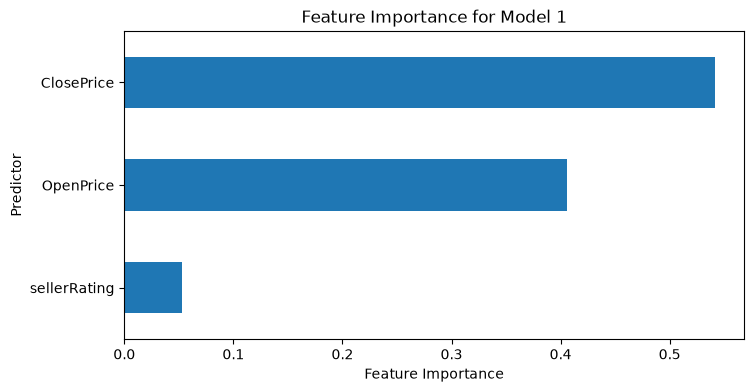

In [8]:
# Plot non-zero feature importance
importance_model1[importance_model1['Importance'] > 0].plot(
    kind='barh',
    x='Feature',
    y='Importance',
    legend=False,
    figsize=(8, 4)
)

plt.xlabel('Feature Importance')
plt.ylabel('Predictor')
plt.title('Feature Importance for Model 1')
plt.gca().invert_yaxis()
plt.show()

### 2.2 Interesting and Unexpected Findings

**Expected findings:**

An expected finding is that auctions with relatively low opening prices and higher closing prices are more likely to be competitive. This makes sense because intuitively, a low opening price may attract more bidders, while a higher closing price may reflect competition among buyers.

**Unexpected findings:**

An interesting finding is that `sellerRating` contributes relatively little to the model, only 5.3% of the total feature importance. Among auctions with an opening price > 10.495 and a closing price > 10, sellers with a 
rating of <= 562 have a higher competitive rate (68.2%) than those with a rating > 562 (26.7%). 
This is surprising, as we would usually expect sellers with higher ratings to attract more customers. 
However, this relationship is conditional on the price-related splits and does not necessarily imply a causal relationship.

It is also surprising that none of the categorical predictors, including category, currency, auction 
duration, and ending day, were selected for splitting. This suggests that price-related information is taking a more dominant role in this full model.

### 2.3 Predictor Reduction

The feature importance results are summarized below:

| Predictor | Feature Importance |
|---|---:|
| ClosePrice | 54.14% |
| OpenPrice | 40.57% |
| sellerRating | 5.30% |
| Other 33 predictors | 0.00% |

As shown, `ClosePrice` and `OpenPrice` are the two most important predictors, together taking over approximately 94.7% of the total feature importance.

If we need to simplify Model 1, the dummy variables associated with category, currency, auction duration, and ending day are possible candidates for removal, as they were not used in any splits.

However, this suggestion applies only to Model 1. Zero feature importance does not necessarily mean that these variables have no predictive power. Once `ClosePrice` is excluded, these variables may become more informative and more useful. Therefore, we will retain them when building Model 2 and reassess their importance.

### 2.4 Practicality of Model 1
This full model is not practical for predicting the competitiveness of a new auction because `ClosePrice`, its most important predictor, is only available after the auction has finished.

Including this variable will introduce **data leakage**, as the model 
uses information that would not be available at the time of prediction (before auction finished). Thus, even if Model 1 achieves high predictive accuracy, its performance may not reflect how well it would predict the competitiveness of a new auction.

To address this issue, we will build a second classification tree that excludes `ClosePrice` and only includes predictors that are available before the auction starts.